# DCGAN on CIFAR-10
**Aim:** Implement and train a Deep Convolutional Generative Adversarial Network (DCGAN) on CIFAR-10, generate synthetic images with the trained generator, and evaluate it using the Generator/Discriminator loss curves and the quality of the generated images.



In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os
os.makedirs('/content/drive/MyDrive/DCGAN', exist_ok=True)
os.chdir('/content/drive/MyDrive/DCGAN')
print('Saving everything to:', os.getcwd())

Mounted at /content/drive
Saving everything to: /content/drive/MyDrive/DCGAN


## 1. Load and visualise the CIFAR-10 dataset

TensorFlow 2.21.0 | Keras 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2841s 17us/step


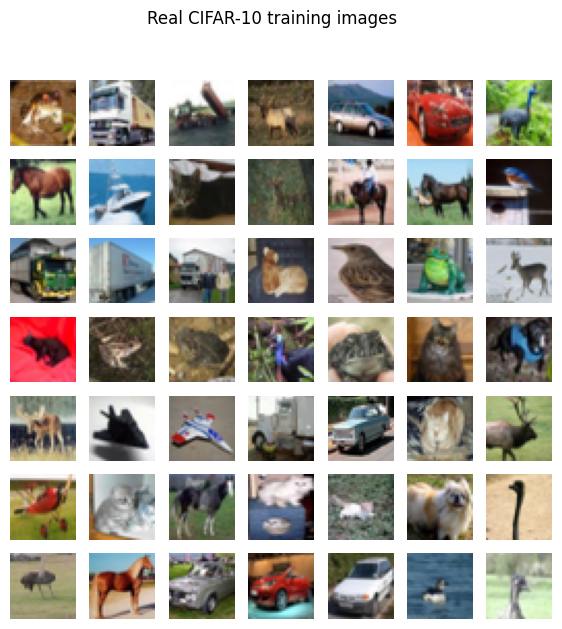

In [3]:
import numpy as np
import tensorflow as tf
import keras
from keras.datasets.cifar10 import load_data
from matplotlib import pyplot

print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

# load the images into memory
(trainX, trainy), (testX, testy) = load_data()

# plot 49 images from the training dataset
pyplot.figure(figsize=(7, 7))
for i in range(49):
    pyplot.subplot(7, 7, 1 + i)
    pyplot.axis('off')
    pyplot.imshow(trainX[i])
pyplot.suptitle('Real CIFAR-10 training images')
pyplot.show()

In [4]:
# shape is an attribute (a tuple), not a function
print('Train:', trainX.shape, trainy.shape)
print('Test :', testX.shape, testy.shape)

Train: (50000, 32, 32, 3) (50000, 1)
Test : (10000, 32, 32, 3) (10000, 1)


## 2. Discriminator
A CNN classifier that takes a 32×32×3 image and outputs the probability that it is **real**.
It uses strided convolutions (no pooling) to downsample, LeakyReLU(0.2) activations and dropout, as recommended for DCGANs.

In [5]:
from keras.models import Sequential
from keras.optimizers import Adam
from keras.layers import Input, Dense, Conv2D, Conv2DTranspose, Flatten, Dropout, LeakyReLU, Reshape
from keras.utils import plot_model

# define the standalone discriminator model
def define_discriminator(in_shape=(32, 32, 3)):
    model = Sequential(name='discriminator')
    model.add(Input(shape=in_shape))
    # normal
    model.add(Conv2D(64, (3, 3), padding='same'))
    model.add(LeakyReLU(negative_slope=0.2))
    # downsample to 16x16
    model.add(Conv2D(128, (3, 3), strides=(2, 2), padding='same'))
    model.add(LeakyReLU(negative_slope=0.2))
    # downsample to 8x8
    model.add(Conv2D(128, (3, 3), strides=(2, 2), padding='same'))
    model.add(LeakyReLU(negative_slope=0.2))
    # downsample to 4x4
    model.add(Conv2D(256, (3, 3), strides=(2, 2), padding='same'))
    model.add(LeakyReLU(negative_slope=0.2))
    # classifier
    model.add(Flatten())
    model.add(Dropout(0.4))
    model.add(Dense(1, activation='sigmoid'))
    # compile model (used for the standalone sanity check below)
    opt = Adam(learning_rate=0.0002, beta_1=0.5)
    model.compile(loss='binary_crossentropy', optimizer=opt, metrics=['accuracy'])
    return model

In [6]:
model = define_discriminator()
model.summary()
try:
    plot_model(model, to_file='discriminator_plot.png', show_shapes=True, show_layer_names=True)
except Exception as e:
    print('plot_model skipped:', e)

Model: "discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 4, 4, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         4,097 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 522,497 (1.99 MB)

 Trainable params: 522,497 (1.99 MB)

 Non-trainable params: 0 (0.00 B)

## 3. Prepare the data
Pixels are scaled from [0, 255] to **[-1, 1]** to match the generator's `tanh` output.

In [7]:
def load_real_samples():
    (trainX, _), (_, _) = load_data()
    X = trainX.astype('float32')
    X = (X - 127.5) / 127.5      # scale from [0,255] to [-1,1]
    return X

X = load_real_samples()
print(X.shape, 'min =', X.min(), 'max =', X.max())

(50000, 32, 32, 3) min = -1.0 max = 1.0


In [8]:
# select real samples; label = 1 because they are real
def generate_real_samples(dataset, n_samples):
    ix = np.random.randint(0, dataset.shape[0], n_samples)
    X = dataset[ix]
    y = np.ones((n_samples, 1))
    return X, y

### Sanity check: can the discriminator tell real images from random noise?

In [9]:
# random-noise 'fake' images in [-1,1] (only for this test)
def generate_noise_samples(n_samples):
    X = np.random.rand(32 * 32 * 3 * n_samples) * 2 - 1
    X = X.reshape((n_samples, 32, 32, 3))
    y = np.zeros((n_samples, 1))
    return X, y

def train_discriminator(model, dataset, n_iter=20, n_batch=128):
    half_batch = int(n_batch / 2)
    for i in range(n_iter):
        X_real, y_real = generate_real_samples(dataset, half_batch)
        _, real_acc = model.train_on_batch(X_real, y_real)
        X_fake, y_fake = generate_noise_samples(half_batch)
        _, fake_acc = model.train_on_batch(X_fake, y_fake)
        print('>%d real=%.0f%% fake=%.0f%%' % (i + 1, real_acc * 100, fake_acc * 100))

model = define_discriminator()
train_discriminator(model, X)

>1 real=20% fake=18%
>2 real=38% fake=35%
>3 real=46% fake=50%
>4 real=54% fake=58%
>5 real=61% fake=65%
>6 real=66% fake=69%
>7 real=69% fake=71%
>8 real=72% fake=74%
>9 real=74% fake=76%
>10 real=76% fake=77%
>11 real=78% fake=79%
>12 real=80% fake=81%
>13 real=81% fake=82%
>14 real=83% fake=83%
>15 real=84% fake=84%
>16 real=85% fake=85%
>17 real=86% fake=86%
>18 real=86% fake=87%
>19 real=87% fake=88%
>20 real=88% fake=88%


## 4. Generator
Maps a 100-dimensional random latent vector to a 32×32×3 image:
Dense → reshape to 4×4×256 → three `Conv2DTranspose` (stride 2) upsampling steps (8×8 → 16×16 → 32×32) → `Conv2D` with **tanh** output in [-1, 1].

In [10]:
def define_generator(latent_dim):
    model = Sequential(name='generator')
    model.add(Input(shape=(latent_dim,)))
    # foundation for 4x4 image
    model.add(Dense(256 * 4 * 4))
    model.add(LeakyReLU(negative_slope=0.2))
    model.add(Reshape((4, 4, 256)))
    # upsample to 8x8
    model.add(Conv2DTranspose(128, (4, 4), strides=(2, 2), padding='same'))
    model.add(LeakyReLU(negative_slope=0.2))
    # upsample to 16x16
    model.add(Conv2DTranspose(128, (4, 4), strides=(2, 2), padding='same'))
    model.add(LeakyReLU(negative_slope=0.2))
    # upsample to 32x32
    model.add(Conv2DTranspose(128, (4, 4), strides=(2, 2), padding='same'))
    model.add(LeakyReLU(negative_slope=0.2))
    # output layer
    model.add(Conv2D(3, (3, 3), activation='tanh', padding='same'))
    return model

latent_dim = 100
model = define_generator(latent_dim)
model.summary()
try:
    plot_model(model, to_file='generator_plot.png', show_shapes=True, show_layer_names=True)
except Exception as e:
    print('plot_model skipped:', e)

Model: "generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 4096)           │       413,696 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_8 (LeakyReLU)       │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 8, 8, 128)      │       524,416 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_9 (LeakyReLU)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 16, 16, 128)    │       262,272 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_10 (LeakyReLU)      │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 32, 32, 128)    │       262,272 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_11 (LeakyReLU)      │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 32, 32, 3)      │         3,459 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,466,115 (5.59 MB)

 Trainable params: 1,466,115 (5.59 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
# points in latent space as input for the generator
def generate_latent_points(latent_dim, n_samples):
    return np.random.randn(n_samples, latent_dim).astype('float32')

# use the generator to make n fake images with label 0
# (calling the model directly is much faster than .predict() inside a loop)
def generate_fake_samples(g_model, latent_dim, n_samples):
    x_input = generate_latent_points(latent_dim, n_samples)
    X = g_model(x_input, training=False).numpy()
    y = np.zeros((n_samples, 1))
    return X, y

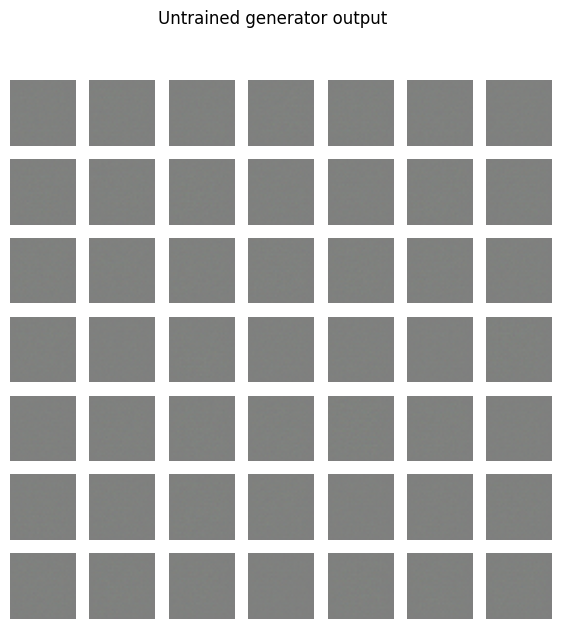

In [12]:
# output of the UNTRAINED generator (should look like noise)
model = define_generator(latent_dim)
Xg, _ = generate_fake_samples(model, latent_dim, 49)
Xg = (Xg + 1) / 2.0
pyplot.figure(figsize=(7, 7))
for i in range(49):
    pyplot.subplot(7, 7, 1 + i)
    pyplot.axis('off')
    pyplot.imshow(Xg[i])
pyplot.suptitle('Untrained generator output')
pyplot.show()

## 5. Training the GAN

**Why a custom training step?** The classic approach builds a combined `gan_model` after setting
`d_model.trainable = False`. In **Keras 3** this flag also freezes the standalone discriminator, so it
never learns. The earlier run showed this: the warning *"The model does not have any trainable weights"*,
and losses stuck at `d1 = d2 ≈ 1.077`, `g ≈ 0.275`.

Here each update uses `tf.GradientTape`, which makes it explicit which network is updated:
1. **Discriminator step:** real images labelled 1, generated images labelled 0 → update **D** only.
2. **Generator step:** generated images labelled **1** (to fool D) → update **G** only, through D.

Both use Adam (lr = 0.0002, β₁ = 0.5) and binary cross-entropy, as in the DCGAN paper.

In [13]:
bce = keras.losses.BinaryCrossentropy()

def make_train_step(g_model, d_model, latent_dim):
    d_opt = Adam(learning_rate=0.0002, beta_1=0.5)
    g_opt = Adam(learning_rate=0.0002, beta_1=0.5)

    @tf.function
    def train_step(real_images):
        half_batch = tf.shape(real_images)[0]

        # ---- 1. update discriminator: real -> 1, fake -> 0 ----
        z = tf.random.normal((half_batch, latent_dim))
        with tf.GradientTape() as tape:
            fake_images = g_model(z, training=True)
            real_out = d_model(real_images, training=True)
            fake_out = d_model(fake_images, training=True)
            d_loss_real = bce(tf.ones_like(real_out), real_out)
            d_loss_fake = bce(tf.zeros_like(fake_out), fake_out)
            d_loss = d_loss_real + d_loss_fake
        grads = tape.gradient(d_loss, d_model.trainable_variables)
        d_opt.apply_gradients(zip(grads, d_model.trainable_variables))

        # ---- 2. update generator: wants D to output 1 for fakes ----
        z = tf.random.normal((2 * half_batch, latent_dim))
        with tf.GradientTape() as tape:
            gen_out = d_model(g_model(z, training=True), training=True)
            g_loss = bce(tf.ones_like(gen_out), gen_out)
        grads = tape.gradient(g_loss, g_model.trainable_variables)
        g_opt.apply_gradients(zip(grads, g_model.trainable_variables))

        # discriminator accuracy on this batch
        acc_real = tf.reduce_mean(tf.cast(real_out > 0.5, tf.float32))
        acc_fake = tf.reduce_mean(tf.cast(fake_out < 0.5, tf.float32))
        return d_loss_real, d_loss_fake, g_loss, acc_real, acc_fake

    return train_step

In [14]:
# create and save a 7x7 plot of generated images
def save_plot(examples, epoch, n=7):
    examples = (examples + 1) / 2.0
    pyplot.figure(figsize=(7, 7))
    for i in range(n * n):
        pyplot.subplot(n, n, 1 + i)
        pyplot.axis('off')
        pyplot.imshow(np.clip(examples[i], 0, 1))
    pyplot.suptitle('Generated images after epoch %d' % (epoch + 1))
    filename = 'generated_plot_e%03d.png' % (epoch + 1)
    pyplot.savefig(filename)
    pyplot.close()

# evaluate D on real & fake, save an image grid and the generator
def summarize_performance(epoch, g_model, d_model, dataset, latent_dim, n_samples=150):
    X_real, y_real = generate_real_samples(dataset, n_samples)
    acc_real = np.mean(d_model(X_real, training=False).numpy() > 0.5)
    x_fake, y_fake = generate_fake_samples(g_model, latent_dim, n_samples)
    acc_fake = np.mean(d_model(x_fake, training=False).numpy() < 0.5)
    print('>Accuracy real: %.0f%%, fake: %.0f%%' % (acc_real * 100, acc_fake * 100))
    save_plot(x_fake, epoch)
    g_model.save('generator_model_%03d.keras' % (epoch + 1))

In [15]:
import time

def train(g_model, d_model, dataset, latent_dim, n_epochs=50, n_batch=128, save_every=5):
    half_batch = n_batch // 2
    train_step = make_train_step(g_model, d_model, latent_dim)
    ds = (tf.data.Dataset.from_tensor_slices(dataset)
          .shuffle(10000).batch(half_batch, drop_remainder=True).prefetch(tf.data.AUTOTUNE))
    bat_per_epo = dataset.shape[0] // half_batch

    history = {'d_real': [], 'd_fake': [], 'g': [], 'acc_real': [], 'acc_fake': []}   # every batch
    epoch_hist = {'d_real': [], 'd_fake': [], 'g': [], 'acc_real': [], 'acc_fake': []}  # epoch means

    for i in range(n_epochs):
        start = time.time()
        ep = {k: [] for k in history}
        for real_batch in ds:
            d1, d2, g, ar, af = train_step(real_batch)
            for k, v in zip(history, (d1, d2, g, ar, af)):
                ep[k].append(float(v))
        for k in history:
            history[k] += ep[k]
            epoch_hist[k].append(float(np.mean(ep[k])))
        print('Epoch %3d/%d  d_real=%.3f  d_fake=%.3f  g=%.3f  D-acc real=%.0f%% fake=%.0f%%  (%.0fs)' % (
            i + 1, n_epochs, epoch_hist['d_real'][-1], epoch_hist['d_fake'][-1], epoch_hist['g'][-1],
            epoch_hist['acc_real'][-1] * 100, epoch_hist['acc_fake'][-1] * 100, time.time() - start))
        if (i + 1) % save_every == 0 or i == 0:
            summarize_performance(i, g_model, d_model, dataset, latent_dim)
    return history, epoch_hist

In [16]:
# ---------------- run training ----------------
# ~50 epochs takes roughly 10-20 min on a Colab T4 GPU. Increase N_EPOCHS (e.g. 100-200) for sharper images.
N_EPOCHS = 50
latent_dim = 100
tf.random.set_seed(42); np.random.seed(42)

d_model = define_discriminator()
g_model = define_generator(latent_dim)
dataset = load_real_samples()

history, epoch_hist = train(g_model, d_model, dataset, latent_dim, n_epochs=N_EPOCHS, n_batch=128)
g_model.save('generator_final.keras')
np.savez('loss_history.npz', **{k: np.array(v) for k, v in history.items()},
         **{'epoch_' + k: np.array(v) for k, v in epoch_hist.items()})

Epoch   1/50  d_real=0.522  d_fake=0.529  g=1.442  D-acc real=71% fake=78%  (63s)
>Accuracy real: 78%, fake: 73%
Epoch   2/50  d_real=0.636  d_fake=0.589  g=1.135  D-acc real=63% fake=72%  (59s)
Epoch   3/50  d_real=0.597  d_fake=0.542  g=1.261  D-acc real=64% fake=78%  (59s)
Epoch   4/50  d_real=0.576  d_fake=0.524  g=1.275  D-acc real=65% fake=80%  (59s)
Epoch   5/50  d_real=0.590  d_fake=0.538  g=1.220  D-acc real=63% fake=79%  (59s)
>Accuracy real: 58%, fake: 99%
Epoch   6/50  d_real=0.611  d_fake=0.567  g=1.083  D-acc real=59% fake=77%  (59s)
Epoch   7/50  d_real=0.633  d_fake=0.605  g=0.937  D-acc real=55% fake=75%  (59s)
Epoch   8/50  d_real=0.646  d_fake=0.620  g=0.910  D-acc real=53% fake=73%  (59s)
Epoch   9/50  d_real=0.653  d_fake=0.632  g=0.877  D-acc real=53% fake=71%  (59s)
Epoch  10/50  d_real=0.648  d_fake=0.630  g=0.892  D-acc real=53% fake=72%  (59s)
>Accuracy real: 41%, fake: 73%
Epoch  11/50  d_real=0.652  d_fake=0.635  g=0.869  D-acc real=53% fake=71%  (59s)
Epoch

## 6. Results

### 6.1 Generator and Discriminator loss curves

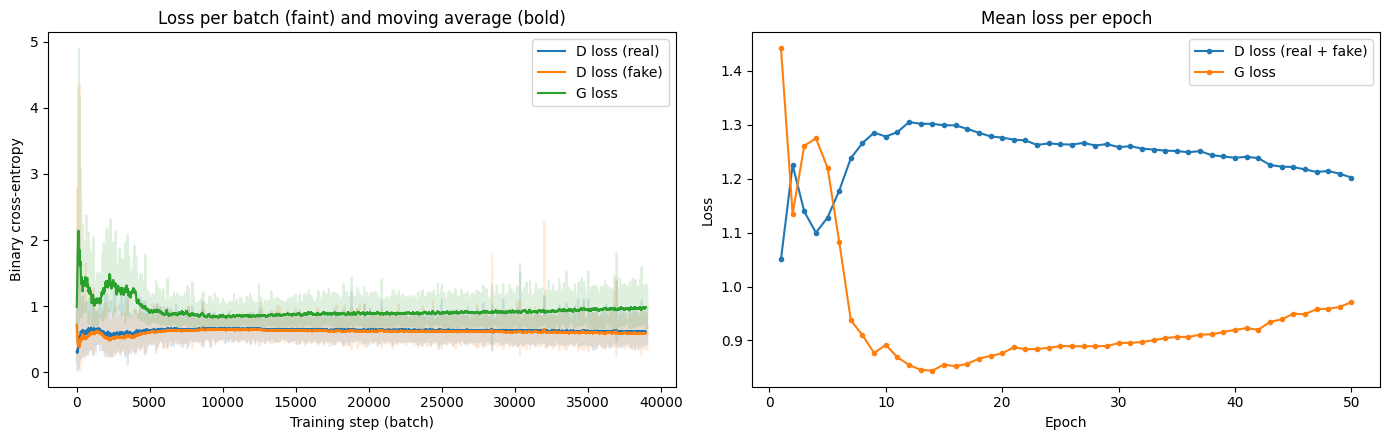

In [17]:
def smooth(y, w=100):
    y = np.asarray(y)
    return np.convolve(y, np.ones(w) / w, mode='valid') if len(y) > w else y

fig, ax = pyplot.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(history['d_real'], alpha=0.15, color='tab:blue')
ax[0].plot(history['d_fake'], alpha=0.15, color='tab:orange')
ax[0].plot(history['g'], alpha=0.15, color='tab:green')
ax[0].plot(smooth(history['d_real']), color='tab:blue', label='D loss (real)')
ax[0].plot(smooth(history['d_fake']), color='tab:orange', label='D loss (fake)')
ax[0].plot(smooth(history['g']), color='tab:green', label='G loss')
ax[0].set_title('Loss per batch (faint) and moving average (bold)')
ax[0].set_xlabel('Training step (batch)'); ax[0].set_ylabel('Binary cross-entropy'); ax[0].legend()

ep = np.arange(1, len(epoch_hist['g']) + 1)
ax[1].plot(ep, np.array(epoch_hist['d_real']) + np.array(epoch_hist['d_fake']), marker='o', ms=3, label='D loss (real + fake)')
ax[1].plot(ep, epoch_hist['g'], marker='o', ms=3, label='G loss')
ax[1].set_title('Mean loss per epoch'); ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Loss'); ax[1].legend()
pyplot.tight_layout(); pyplot.savefig('loss_curves.png', dpi=150); pyplot.show()

### 6.2 Discriminator accuracy on real and generated images

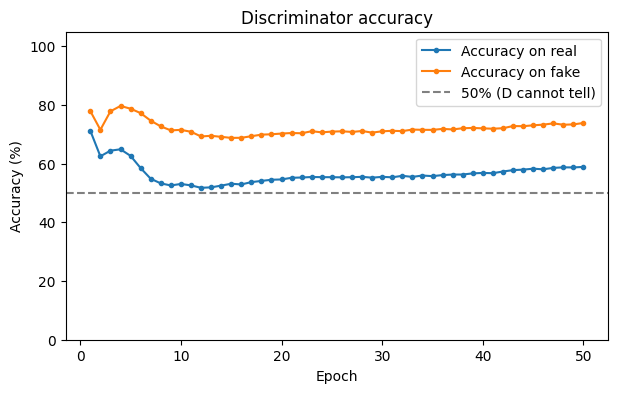

In [18]:
pyplot.figure(figsize=(7, 4))
pyplot.plot(ep, np.array(epoch_hist['acc_real']) * 100, marker='o', ms=3, label='Accuracy on real')
pyplot.plot(ep, np.array(epoch_hist['acc_fake']) * 100, marker='o', ms=3, label='Accuracy on fake')
pyplot.axhline(50, ls='--', color='gray', label='50% (D cannot tell)')
pyplot.xlabel('Epoch'); pyplot.ylabel('Accuracy (%)'); pyplot.ylim(0, 105)
pyplot.title('Discriminator accuracy'); pyplot.legend()
pyplot.savefig('discriminator_accuracy.png', dpi=150); pyplot.show()

### 6.3 Synthetic images from the trained generator

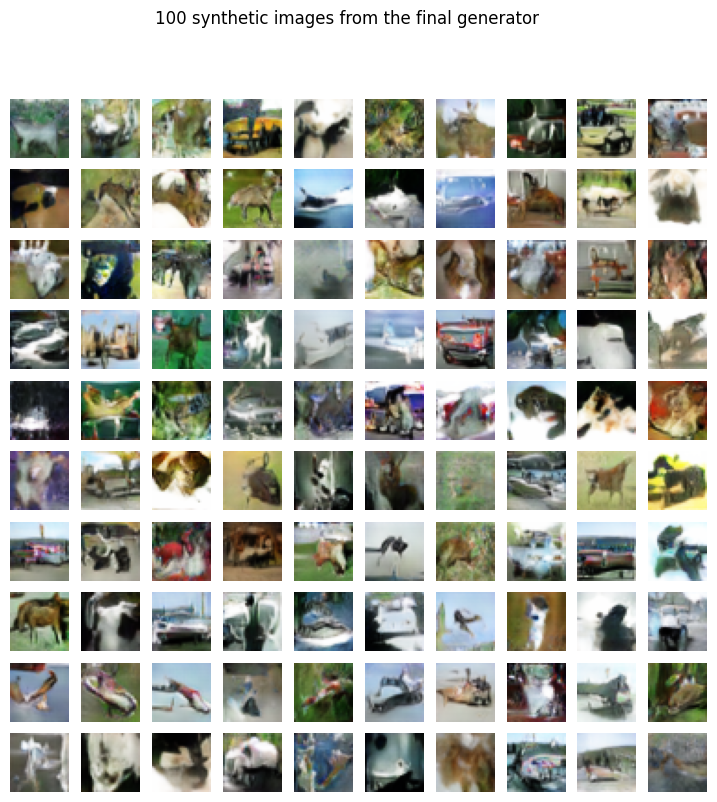

In [19]:
final_g = keras.models.load_model('generator_final.keras')
n = 10
Xf, _ = generate_fake_samples(final_g, latent_dim, n * n)
Xf = np.clip((Xf + 1) / 2.0, 0, 1)
pyplot.figure(figsize=(9, 9))
for i in range(n * n):
    pyplot.subplot(n, n, 1 + i); pyplot.axis('off'); pyplot.imshow(Xf[i])
pyplot.suptitle('100 synthetic images from the final generator')
pyplot.savefig('final_generated_images.png', dpi=150); pyplot.show()

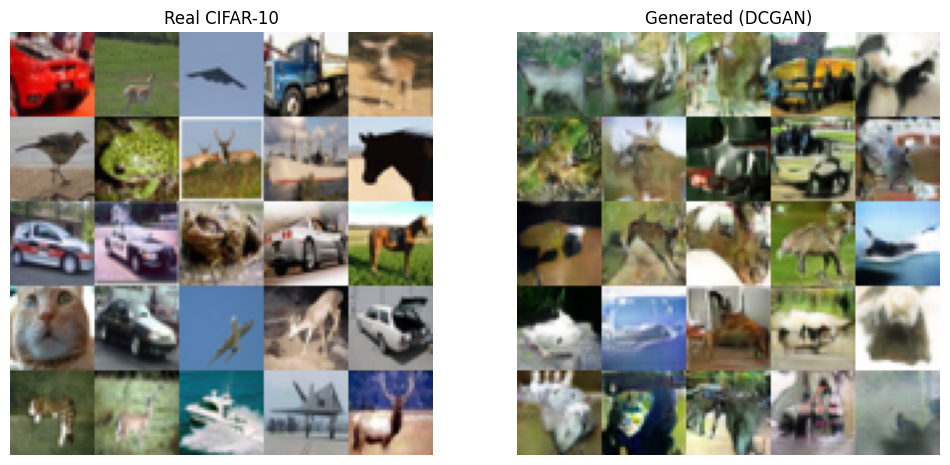

In [20]:
# side-by-side: real vs generated
Xr, _ = generate_real_samples(dataset, 25)
Xr = (Xr + 1) / 2.0
fig, ax = pyplot.subplots(1, 2, figsize=(12, 6))
for a, imgs, title in [(ax[0], Xr, 'Real CIFAR-10'), (ax[1], Xf[:25], 'Generated (DCGAN)')]:
    grid = imgs.reshape(5, 5, 32, 32, 3).transpose(0, 2, 1, 3, 4).reshape(160, 160, 3)
    a.imshow(grid); a.set_title(title); a.axis('off')
pyplot.savefig('real_vs_generated.png', dpi=150); pyplot.show()

### 6.4 How image quality improved during training

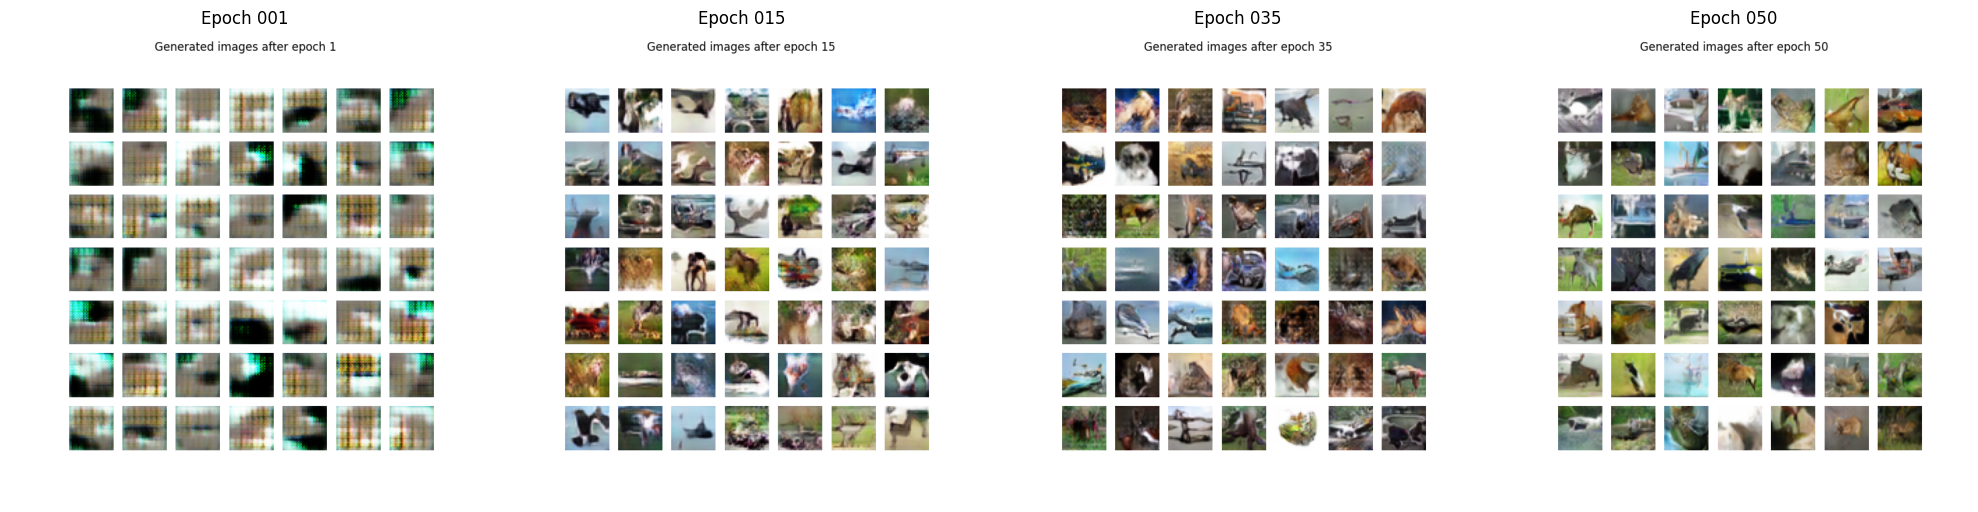

In [21]:
import glob, matplotlib.image as mpimg
files = sorted(glob.glob('generated_plot_e*.png'))
pick = [files[0], files[len(files) // 3], files[2 * len(files) // 3], files[-1]] if len(files) >= 4 else files
fig, ax = pyplot.subplots(1, len(pick), figsize=(5 * len(pick), 5))
for a, f in zip(np.atleast_1d(ax), pick):
    a.imshow(mpimg.imread(f)); a.axis('off'); a.set_title(f.replace('generated_plot_e', 'Epoch ').replace('.png', ''))
pyplot.tight_layout(); pyplot.savefig('training_progression.png', dpi=120); pyplot.show()

## 7. Analysis


**Loss curves**
- At the start, D loss drops quickly because the generator only produces noise, which is easy to reject. G loss rises at the same time.
- After the first few epochs both losses **stop trending and oscillate around a level**. This is the expected behaviour of a GAN: G and D play a minimax game, so neither loss goes to zero. A stable band, rather than one loss going to 0 while the other explodes, shows the training is **balanced**.
- For reference, at the theoretical equilibrium D outputs 0.5 everywhere: D loss (real + fake) = 2·ln 2 ≈ **1.39** and G loss = ln 2 ≈ **0.69**. In practice D stays somewhat stronger, so G loss is usually higher (around 1–2.5).
- Warning signs to look for: D loss → 0 with G loss climbing steadily (D wins and G stops learning), or sudden spikes (instability).

**Discriminator accuracy**
- Accuracy that stays roughly between 60% and 90%, rather than at 100%, means the generator is producing images realistic enough to fool D some of the time.

**Quality of generated images**
- Early epochs: blurry colour blobs. Middle epochs: CIFAR-like colours, backgrounds (sky, grass) and rough object shapes. Final epochs: recognisable shapes such as animals, cars, ships and horses, though with distorted details. This is typical for a small DCGAN at 32×32.
- The samples are **varied** (different colours, backgrounds and objects). If many samples looked nearly identical, that would indicate **mode collapse**.
- Limitations: objects are often not clearly identifiable, and fine details (faces, wheels) are smudged. Longer training (100–200 epochs), BatchNorm in the generator, or label smoothing would improve quality. A quantitative metric such as **FID** or **Inception Score** could be added for a formal evaluation.

**Conclusion**
The DCGAN learned to map random 100-D noise vectors to 32×32 colour images that resemble the CIFAR-10 distribution. The oscillating but stable loss curves and the discriminator accuracy staying below 100% confirm adversarial training worked as intended.